# 05 · Hyperliquid: lo stesso test su un mercato crypto L4 (E4)

**Hyperliquid** è un exchange decentralizzato di contratti perpetui. Il dataset di Albers et al. (2026) registra ogni modifica del book con il singolo ordine **e l'utente** che lo ha inserito: è un dato **L4**, più dettagliato dell'ITCH.

C'è una difficoltà: quando un ordine sparisce dal book, il dato non dice se è stato eseguito o cancellato. Il parser lo ricava incrociando il book con l'elenco pubblico degli scambi: ogni scambio indica l'ordine passivo coinvolto, quindi si sa quanta parte di una rimozione è un'esecuzione.

**Dati:** BTC-PERP, sei ore (1-3 dicembre 2025, ore 08 e 14 UTC). Calibrazione 1/12 ore 08, validazione 1/12 ore 14, test le quattro ore successive. Quota di 0,01 BTC per lato. I dati non hanno orari, quindi durate e latenze sono in **eventi** (circa 700 al secondo).

I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")                      # sessioni di test, strategia selezionata
validation = R.load(ROOT, "validation")          # griglia di parametri sulle sessioni di validazione
ablation = R.load(ROOT, "ablation")              # test ripetuto senza filtro di volatilità
variants = R.load(ROOT, "variants")              # varianti: inventory skew e imbalance
selected = R.load_json(ROOT, "selected_params")  # parametri scelti in validazione

def bias_figure(name, stats, unit, filename):
    """P&L per regola e rapporto tra esecuzioni L2 ed esecuzioni con la coda."""
    bias = R.fill_bias(test, name).median()
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
    R.bar_by_model(axes[0], stats, "P&L lordo medio per sessione (IC 95%)", unit)
    linthresh = 10 ** np.ceil(np.log10(max(1.0, abs(stats.loc["coda FIFO", "media"]))))
    axes[0].set_yscale("symlog", linthresh=linthresh, linscale=0.5)
    axes[1].bar([R.LABELS[m] for m in bias.index], bias, color=[R.COLORS[m] for m in bias.index], width=0.6)
    for k, v in enumerate(bias):
        axes[1].text(k, v * 1.08, f"{it(v, 1)}×", ha="center", va="bottom", color=R.INK)
    axes[1].axhline(1, color=R.INK, linewidth=0.8)
    axes[1].set(yscale="log", title="Esecuzioni rispetto alla coda FIFO (mediana)", ylim=(0.5, bias.max() * 3))
    axes[1].grid(axis="x", visible=False)
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches="tight")
    plt.show()
    return bias

stats = R.model_table(test, "hyperliquid")
queue = test[(test.dataset == "hyperliquid") & (test.model == "queue")]
ingest = pd.DataFrame(R.load_json(ROOT, "ingest/hyperliquid")["sessions"]).set_index("session")
R.show_box("In breve", [
    f"Il {pct((ingest.fill_volume / ingest.trade_volume).min(), 0)}-{pct((ingest.fill_volume / ingest.trade_volume).max(), 0)} del volume scambiato viene ricondotto a ordini del book.",
    f"Con la coda reale la strategia perde in media {it(-queue.net_tier0.mean(), 1)} USD netti per ora, in {it((queue.net_tier0 < 0).sum())} ore su {len(queue)}.",
    "Lo spread di BTC è quasi sempre di un dollaro: lo spread incassato è minimo rispetto alle commissioni.",
])

> **In breve**
>
> - Il 97%-99% del volume scambiato viene ricondotto a ordini del book.
> - Con la coda reale la strategia perde in media 47,3 USD netti per ora, in 4 ore su 4.
> - Lo spread di BTC è quasi sempre di un dollaro: lo spread incassato è minimo rispetto alle commissioni.

## 1. Dai dati grezzi agli eventi

Per ogni ora: quante modifiche del book riguardano BTC, quante rimozioni risultano esecuzioni o cancellazioni e quanta parte del volume scambiato viene attribuita. Le modifiche su ordini inseriti prima dell'inizio dell'ora non si possono collegare a nulla e vengono scartate.

In [2]:
quality = R.load(ROOT, "quality").query("dataset == 'hyperliquid'").set_index("session")
display(pd.DataFrame({
    "modifiche del book BTC": ingest.diffs.map(lambda v: it(v)),
    "esecuzioni": ingest.fill_events.map(lambda v: it(v)),
    "cancellazioni": ingest.cancel_events.map(lambda v: it(v)),
    "volume scambiato attribuito": (ingest.fill_volume / ingest.trade_volume).map(lambda v: pct(v, 1)),
    "modifiche su ordini precedenti": ingest.unknown_order_diffs.map(lambda v: it(v)),
    "book incrociato": quality.crossed_share.map(lambda v: pct(v, 2)),
}))

,modifiche del book BTC,esecuzioni,cancellazioni,volume scambiato attribuito,modifiche su ordini precedenti,book incrociato
session,,,,,,
20251201T08,2.420.117,17.444,1.186.941,"98,3%",14.751,"0,00%"
20251201T14,4.031.702,36.484,1.967.011,"99,4%",30.667,"0,00%"
20251202T08,2.470.744,23.698,1.205.535,"96,5%",17.800,"0,00%"
20251202T14,4.808.729,49.791,2.339.637,"97,2%",41.821,"0,00%"
20251203T08,2.622.419,19.658,1.285.047,"97,8%",16.569,"0,00%"
20251203T14,5.536.288,64.993,2.687.374,"96,8%",50.401,"0,00%"


## 2. Scelta dei parametri (validazione)

P&L netto medio (USD, commissioni di livello base) sull'ora di validazione, con la coda FIFO.

In [3]:
display(R.validation_grid(validation, "hyperliquid", "net_tier0").style.format("{:.1f}").background_gradient(cmap="Greys", axis=None))
display(Markdown(f"**Parametri scelti:** {R.params_text('hyperliquid', selected['hyperliquid']['params'])}."))

**Parametri scelti:** volatilità su una finestra di 5.000 eventi; si opera solo sotto il 50° percentile della volatilità di calibrazione; ogni quota resta nel book al massimo 5.000 eventi.

## 3. Risultati: coda reale contro regole L2

,P&L medio per sessione (IC 95%),sessioni positive,sessioni
touch,"3.814,26 (2.798,01; 4.830,51)",100%,4
price-through,"-32,58 (-35,34; -29,82)",0%,4
cross,"-28,60 (-32,09; -25,50)",0%,4
coda FIFO,"-3,25 (-3,88; -2,18)",0%,4


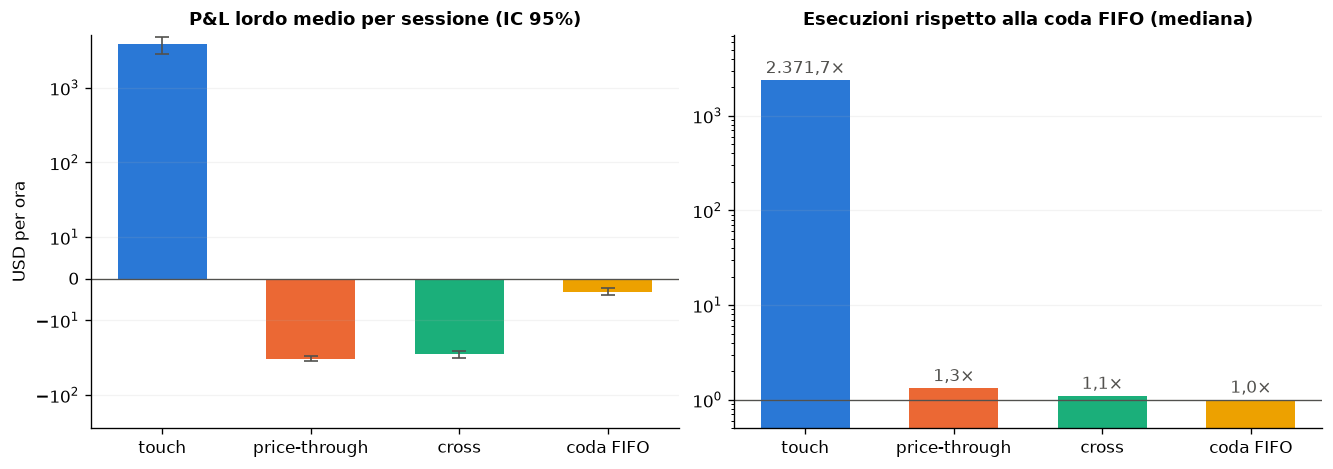

**Come leggerlo.** Qui la distorsione di `touch` è ancora più grande: 2.372 volte le esecuzioni della coda. Su BTC il prezzo resta fermo per moltissimi eventi consecutivi e `touch` considera eseguita la quota a ogni evento in cui il miglior prezzo non si allontana.

In [4]:
display(R.results_table(stats, 2))
bias = bias_figure("hyperliquid", stats, "USD per ora", "hyperliquid_test.png")
display(Markdown(
    f"**Come leggerlo.** Qui la distorsione di `touch` è ancora più grande: {it(bias['touch'])} volte le esecuzioni "
    "della coda. Su BTC il prezzo resta fermo per moltissimi eventi consecutivi e `touch` considera eseguita la quota "
    "a ogni evento in cui il miglior prezzo non si allontana."))

## 4. Perché la strategia perde

In [5]:
dec = R.decomposition(test, "hyperliquid", "fees_tier0")
display(R.decomposition_table(dec, 2))
from market_making_tesi.pipeline import DATASETS, events, l2_view, session_list
spec = DATASETS["hyperliquid"]
path = next(p for s, sym, p in session_list(ROOT, spec) if s == "20251202T08")
spreads = np.fromiter((s.spread for s in l2_view(events(spec, path, "BTC"))), dtype=float)
d = dec.loc["coda FIFO"]
display(Markdown(
    f"**Come leggerlo.** Lo spread è di un dollaro (su circa 90.000) {R.nel((spreads <= 1.0 + 1e-9).mean(), 0)} degli "
    f"eventi: una coppia completa rende pochissimo. Lo spread incassato ({it(d['maker_edge'], 2)} USD per ora) è "
    f"trascurabile rispetto alle commissioni ({it(-d['fees'], 2)} USD), che da sole spiegano quasi tutta la perdita."))

,spread incassato (edge maker),costo di liquidazione,movimento del prezzo sull'inventario,= P&L lordo,commissioni e rebate,= P&L netto
touch,"3.836,85","-5,46","-17,13","3.814,26","-97.692,69","-93.878,43"
price-through,"-0,08","-7,65","-24,84","-32,58","-190,31","-222,89"
cross,"-7,99","-5,54","-15,06","-28,60","-164,18","-192,78"
coda FIFO,"0,59","-1,27","-2,57","-3,25","-44,04","-47,28"


**Come leggerlo.** Lo spread è di un dollaro (su circa 90.000) nel 96% degli eventi: una coppia completa rende pochissimo. Lo spread incassato (0,59 USD per ora) è trascurabile rispetto alle commissioni (44,04 USD), che da sole spiegano quasi tutta la perdita.

## 5. Filtro di volatilità e varianti

In [6]:
display(Markdown("**Con filtro e sempre attiva** (P&L netto per ora, USD)"))
display(R.filter_table(R.filter_effect(test, ablation, "hyperliquid", "net_tier0"), 2))
display(Markdown("**Varianti** (P&L netto per ora, USD)"))
display(R.variants_table(R.variant_effect(test, variants, "hyperliquid", "net_tier0", fee_column="fees_tier0"), 2))
display(Markdown(
    "**Come leggerlo.** Su Hyperliquid il filtro di volatilità e quello di imbalance migliorano il risultato "
    "soprattutto perché la strategia **opera meno** e paga meno commissioni: perde meno, ma non diventa profittevole."))

**Con filtro e sempre attiva** (P&L netto per ora, USD)

,con filtro,sempre attiva,differenza (IC 95%),sessioni migliori con filtro,tempo in cui opera
modello,,,,,
touch,"-93.878,43","-152.200,57","58.322,14 (21.229,30; 95.414,99)",100%,32%
price-through,"-222,89","-527,89","305,00 (75,00; 535,01)",100%,32%
cross,"-192,78","-525,62","332,84 (87,90; 577,78)",100%,32%
coda FIFO,"-47,28","-122,34","75,05 (22,26; 127,84)",100%,32%


**Varianti** (P&L netto per ora, USD)

,P&L netto medio (IC 95%),sessioni positive,differenza vs base (IC 95%),liquidazioni a mercato per sessione
variante,,,,
base,"-47,28 (-56,71; -34,16)",0%,—,118
inventory skew,"-39,33 (-44,33; -31,14)",0%,"7,95 (1,72; 14,18)",92
filtro di imbalance,"-6,40 (-9,87; -3,92)",0%,"40,88 (28,79; 49,76)",14
skew + imbalance,"-5,64 (-8,43; -3,58)",0%,"41,65 (29,50; 50,35)",11


**Come leggerlo.** Su Hyperliquid il filtro di volatilità e quello di imbalance migliorano il risultato soprattutto perché la strategia **opera meno** e paga meno commissioni: perde meno, ma non diventa profittevole.